# GraphCast vs AIFS: 2025 Tennessee Valley Flood (ERA5-initialized)

A controlled comparison of two AI weather models on the April 2025 Tennessee Valley flood, when days of repeated heavy rain flooded the Ohio and Tennessee valleys. Google DeepMind's GraphCast Operational and ECMWF's AIFS are both run through NVIDIA Earth2Studio from the same ERA5/ARCO state (ERA5 from Google's ARCO archive, the `ARCO_ERA5` data source) at 2025-04-01 00Z, for 20 six-hourly steps (to 2025-04-06 00Z). Because the initial condition is shared, the model is the only difference (the WeatherBench 2 same-analysis convention). The two forecasts are compared on daily precipitation maps, at cities, and against ERA5 daily precipitation over the Tennessee Valley box (33–40.5°N, 95–82°W). "AIFS" here is AIFS v1 (AIFS Single; Earth2Studio 0.20.0 loads its `aifs-single-1.1` checkpoint), not the newer AIFS 2.

> **Measured on an NVIDIA L40:** _filled in after the verified run._

1. Setup
2. Configuration
3. Run GraphCast
4. Run AIFS v1
5. Daily precipitation and map helpers
6. Verify against ERA5
7. Daily maps
8. Side-by-side comparison — maps, city table, domain max
9. Nashville time series

## 1 · Setup

Both models read their initial state from ERA5 on ARCO (no credentials needed); the ERA5 precipitation used for scoring in section 6 comes from the Copernicus Climate Data Store and needs `~/.cdsapirc`. The `aifs` and `graphcast` extras of earth2studio, installed by `uv sync`, bring the AIFS v1 stack (`anemoi-models` 0.5.1) and GraphCast's JAX stack, so no extra `pip install` is needed.

GraphCast runs in JAX and AIFS in PyTorch inside the same kernel. `XLA_PYTHON_CLIENT_PREALLOCATE=false` stops JAX from reserving most of the GPU up front, and `free_gpu(...)` releases each model after its run. If AIFS runs out of GPU memory after GraphCast, restart the kernel and run all cells again: GraphCast's forecast is then read back from its Zarr store and AIFS has the GPU to itself.

In [2]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # jax (GraphCast) + torch (AIFS) share GPU

import gc
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr

import earth2studio.run as run
from earth2studio.data import ARCO_ERA5
from earth2studio.io import ZarrBackend
from earth2studio.models.px import AIFS, GraphCastOperational

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


class _ZarrIO:
    """Minimal io-like wrapper so the compute/plot helpers work on an opened Zarr store."""

    def __init__(self, ds):
        self.ds = ds

    def __getitem__(self, key):
        return self.ds[key].values

/home/jovyan/flood-forecasts/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 2 · Configuration

Every value a reader may want to change lives here: the shared initial time, the days compared, the region, the cities, and where the two forecasts are stored.

In [1]:
# Event and shared forecast setup
EVENT_NAME = "2025 Tennessee Valley Flood"
FORECAST_INIT = "2025-04-01T00:00:00"
NSTEPS = 20  # 20 x 6h = Apr 1 00Z -> Apr 6 00Z (covers the April 5 daily total)

# Days compared: ERA5 scores and the Nashville series use COMPARE_DATES; maps and the city table use COMPARE_DATES_2M
COMPARE_DATES = ["2025-04-02", "2025-04-03", "2025-04-04", "2025-04-05"]
COMPARE_DATES_2M = ["2025-04-04", "2025-04-05"]

# Tennessee Valley region [lon_min, lon_max, lat_min, lat_max]; also the ERA5 scoring box (era5_truth.TN_BOX)
EXTENT = [-95, -82, 33, 40.5]

# Point for the time series (longitude in 0-360)
POI_LAT = 36.16
POI_LON = 360 - 86.78
POI_LABEL = "Nashville, TN"

# Cities marked on the maps and listed in the city table
CITIES = [
    {"lat": 39.78, "lon": 360 - 89.65, "label": "Springfield, IL"},
    {"lat": 39.77, "lon": 360 - 86.16, "label": "Indianapolis, IN"},
    {"lat": 39.10, "lon": 360 - 84.51, "label": "Cincinnati, OH"},
    {"lat": 38.63, "lon": 360 - 90.20, "label": "St Louis, MO"},
    {"lat": 38.25, "lon": 360 - 85.76, "label": "Louisville, KY"},
    {"lat": 36.37, "lon": 360 - 94.21, "label": "Bentonville, AR"},
    {"lat": 35.15, "lon": 360 - 90.05, "label": "Memphis, TN"},
]

# Outputs (paths relative to the notebook folder). A forecast whose Zarr store exists is read back, not re-run.
PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUTPUT_DIR = "tn_model_compare_outputs"
GRAPHCAST_ZARR = f"{OUTPUT_DIR}/graphcast_tn_era5_ic0401.zarr"
AIFS_ZARR = "aifs_tn_flood_outputs/aifs_tn_ic0401.zarr"  # kept in its own folder
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3 · Run GraphCast

If GraphCast's Zarr store already exists, the forecast is read back instead of re-run (rename or delete the folder to force a new run). Otherwise the model is loaded, run from the ERA5 state with only `tp06` (6-hour precipitation) kept, and released.

In [4]:
if os.path.exists(GRAPHCAST_ZARR):
    print("Reusing existing GraphCast forecast:", GRAPHCAST_ZARR)
    gc_io = _ZarrIO(xr.open_zarr(GRAPHCAST_ZARR, consolidated=False))
else:
    try:
        gc_package = GraphCastOperational.load_default_package()
        gc_model = GraphCastOperational.load_model(gc_package)
        gc_store = ZarrBackend(GRAPHCAST_ZARR, backend_kwargs={"overwrite": True})
        gc_io = run.deterministic(
            [FORECAST_INIT], NSTEPS, gc_model, ARCO_ERA5(), gc_store,
            output_coords={"variable": np.array(["tp06"])},
        )
    finally:
        free_gpu("gc_model", "gc_package")

print("GraphCast tp06 shape:", gc_io["tp06"].shape)

2026-07-07 02:08:29.656 | INFO     | earth2studio.run:deterministic:87 - Running simple workflow!
2026-07-07 02:08:29.657 | INFO     | earth2studio.run:deterministic:94 - Inference device: cuda
2026-07-07 02:08:29.742 | DEBUG    | earth2studio.data.arco:_async_init:128 - Using Multi-Storage Client for ARCO data access


Fetching ARCO data:   0%|                                                                                        | 0/10 [00:00<?, ?it/s]

Fetching ARCO data:  10%|████████                                                                        | 1/10 [00:00<00:03,  2.83it/s]

Fetching ARCO data:  50%|████████████████████████████████████████                                        | 5/10 [00:00<00:00,  5.39it/s]

Fetching ARCO data:  60%|████████████████████████████████████████████████                                | 6/10 [00:01<00:00,  4.97it/s]

Fetching ARCO data: 100%|███████████████████████████████████████████████████████████████████████████████| 10/10 [00:01<00:00,  8.13it/s]

... (26 outputs left out)

Running inference:  95%|████████████████████████████████████████████████████████████████████████████▏   | 20/21 [01:41<00:01,  1.33s/it]

Running inference: 100%|████████████████████████████████████████████████████████████████████████████████| 21/21 [01:42<00:00,  1.31s/it]

Running inference: 100%|████████████████████████████████████████████████████████████████████████████████| 21/21 [01:42<00:00,  4.88s/it]

2026-07-07 02:10:16.955 | SUCCESS  | earth2studio.run:deterministic:191 - 
Inference complete
GraphCast tp06 shape: (1, 21, 721, 1440)


## 4 · Run AIFS v1

The same pattern for AIFS: it runs whenever its Zarr store is missing, from the same ERA5 state and for the same 20 steps.

In [6]:
if os.path.exists(AIFS_ZARR):
    print("Reusing existing AIFS forecast:", AIFS_ZARR)
    aifs_io = _ZarrIO(xr.open_zarr(AIFS_ZARR, consolidated=False))
else:
    try:
        aifs_package = AIFS.load_default_package()
        aifs_model = AIFS.load_model(aifs_package)
        aifs_store = ZarrBackend(AIFS_ZARR, backend_kwargs={"overwrite": True})
        aifs_io = run.deterministic(
            [FORECAST_INIT], NSTEPS, aifs_model, ARCO_ERA5(), aifs_store,
            output_coords={"variable": np.array(["tp06"])},
        )
    finally:
        free_gpu("aifs_model", "aifs_package")

print("AIFS tp06 shape:", aifs_io["tp06"].shape)

Reusing existing AIFS forecast: aifs_tn_flood_outputs/aifs_tn_ic0401.zarr


AIFS tp06 shape: (1, 21, 721, 1440)


## 5 · Daily precipitation and map helpers

For both models each `tp06` value is the rain (in metres) that fell in the 6 hours ending at that step's valid time; step 0 is the initial state and is all zeros. A UTC day D is the sum of the four steps valid at D 06Z, 12Z, 18Z and D+1 00Z, which is the window (D 00Z, D+1 00Z]. The ERA5 daily totals in section 6 use the same window.

In [7]:
def compute_daily_total_precip(store, target_date, init_time, variable="tp06", dt_hours=6):
    """Precipitation total (mm) for the UTC day `target_date`, i.e. over (D 00Z, D+1 00Z].

    Each `tp06` step holds the rain of the 6 hours ending at its valid time (step 0 is all zeros), so day D
    is the sum of the steps valid at D 06Z, 12Z, 18Z and D+1 00Z, the same window as the ERA5 daily totals.
    """
    steps_per_day = 24 // dt_hours
    tp = store[variable]
    first_step = int((np.datetime64(target_date) - np.datetime64(init_time)) / np.timedelta64(dt_hours, "h")) + 1
    last_step = first_step + steps_per_day - 1
    if first_step < 1 or last_step > tp.shape[1] - 1:
        raise ValueError(f"{target_date} is not fully covered by the forecast from {init_time}.")

    total = np.zeros_like(tp[0, first_step])
    for step in range(first_step, last_step + 1):
        total += tp[0, step] * 1000.0  # metres -> millimetres
    return np.clip(total, 0, None)

In [8]:
PRECIP_LEVELS = [1, 5, 10, 20, 30, 50, 75, 100, 150]
PRECIP_CMAP = plt.cm.rainbow_r  # red = light rain, blue-purple = heavy rain
PRECIP_NORM = mcolors.BoundaryNorm(PRECIP_LEVELS, PRECIP_CMAP.N, extend="max")


def _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=None):
    """Draw one daily-precip field onto a cartopy axes; return the contourf mappable."""
    # extend="max" colours totals above the top level instead of leaving them blank
    im = ax.contourf(
        lon, lat, precip,
        levels=PRECIP_LEVELS, cmap=PRECIP_CMAP, norm=PRECIP_NORM,
        transform=ccrs.PlateCarree(), extend="max",
    )
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.coastlines(linewidth=0.8)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax.set_extent(extent)

    for city in poi or []:
        ax.plot(
            city["lon"] - 360, city["lat"],
            marker="*", color="lime", markersize=7,
            markeredgecolor="black", markeredgewidth=0.5,
            transform=ccrs.PlateCarree(), zorder=5,
        )
        ax.text(
            city["lon"] - 360 + 0.15, city["lat"] + 0.15, city["label"],
            fontsize=7, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8),
            transform=ccrs.PlateCarree(), zorder=5,
        )
    ax.set_title(label, fontsize=11)
    return im


def _add_precip_colorbar(im, ax):
    """Horizontal colour bar under one map."""
    cbar = plt.colorbar(im, ax=ax, shrink=0.55, pad=0.04, orientation="horizontal")
    cbar.set_label("Total Precipitation (mm)", fontsize=10)
    cbar.ax.tick_params(labelsize=8)


def plot_single_panel(precip, label, lon, lat, extent, poi=None, save_path=None):
    """One daily-precip map in the tall house layout."""
    plt.close("all")

    fig, ax = plt.subplots(
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 8),
    )
    _add_precip_colorbar(_draw_precip_axes(ax, precip, label, lon, lat, extent, poi=poi), ax)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def domain_max_location(field, lon, lat, extent):
    """Max precip within the plotted extent and its (lat, lon), lon in -180..180 degrees."""
    lon_min, lon_max = extent[0] + 360, extent[1] + 360   # -95, -82 -> 265, 278
    lat_min, lat_max = extent[2], extent[3]
    lat_sel = (lat >= lat_min) & (lat <= lat_max)
    lon_sel = (lon >= lon_min) & (lon <= lon_max)
    sub = field[np.ix_(lat_sel, lon_sel)]
    i, j = np.unravel_index(np.argmax(sub), sub.shape)
    return float(sub[i, j]), float(lat[lat_sel][i]), float(lon[lon_sel][j] - 360)


def plot_model_comparison(precip_gc, precip_ai, date, lon, lat, extent, poi, save_path=None):
    """GraphCast (top) vs AIFS (bottom) on the same rainbow_r scale and levels (tall layout)."""
    plt.close("all")

    fig, axes = plt.subplots(
        2, 1, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(6, 9),
    )
    for ax, precip, name in zip(axes, [precip_gc, precip_ai], ["GraphCast", "AIFS v1"]):
        _add_precip_colorbar(_draw_precip_axes(ax, precip, f"{name} | {date}", lon, lat, extent, poi=poi), ax)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

## 6 · Verify against ERA5

Which model is closer to an independent estimate of the rain that fell? Each model's daily totals for April 2–5 are compared with ERA5 daily totals for the same UTC windows (section 5) over the Tennessee Valley box (33–40.5°N, 95–82°W, `era5_truth.TN_BOX`) on the model grid. Hourly ERA5 precipitation comes from the Copernicus Climate Data Store (it needs `~/.cdsapirc` credentials) and is cached in `OUTPUT_DIR`; the same daily fields fill the ERA5 column of the city table in section 8.

> **Truth caveat:** ERA5 precipitation is itself model-derived (it is a reanalysis product), so these scores measure agreement with ERA5, not with rain gauges or radar. Both forecasts also start from ERA5, so neither model has an advantage from the reference.

**How to read the tables.** The first table has one row per model and day; the second averages April 2–5 for each model. Bias = forecast − ERA5 in mm/day (positive means too wet), averaged over the box with area weights; RMSE and MAE are the typical size of the point-by-point error in mm/day; Pattern corr = spatial correlation of the daily rainfall pattern (1 means the rain is in the right places, whatever the amounts). Both models have the same lead times, so differences between the rows come from the models.

In [ ]:
from era5_truth import TN_ERA5_AREA, fetch_era5_daily_precip, forecast_vs_era5
from metrics import skill_row

era5_daily = fetch_era5_daily_precip(COMPARE_DATES, TN_ERA5_AREA, f"{OUTPUT_DIR}/era5_tp_tn.nc")

rows = []
for date in COMPARE_DATES:
    for model, run_store in (("GraphCast", gc_io), ("AIFS", aifs_io)):
        fc, ref, lats = forecast_vs_era5(
            compute_daily_total_precip(run_store, date, FORECAST_INIT),
            era5_daily.sel(day=np.datetime64(date)), run_store["lat"][:], run_store["lon"][:],
        )
        rows.append({"Model": model, "Date": date, **skill_row(fc, ref, lats)})

daily_skill = pd.DataFrame(rows)
metrics_df = (
    daily_skill.groupby("Model")[["Bias", "RMSE", "MAE", "Pattern corr"]].mean().round(3).reset_index()
)
daily_skill.to_csv(RESULTS_DIR / "tennessee_valley_flood_model_comparison_daily.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "tennessee_valley_flood_model_comparison_metrics.csv", index=False)
print("Daily skill vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)\n")
print(daily_skill.to_string(index=False))
print("\nMean over Apr 2-5\n")
print(metrics_df.to_string(index=False))

## 7 · Daily maps

Each model's daily totals for the last two forecast days, when the flood-producing rain was falling, on identical maps.

### GraphCast daily maps


Saved: tn_model_compare_outputs/graphcast_daily_2025-04-04.png


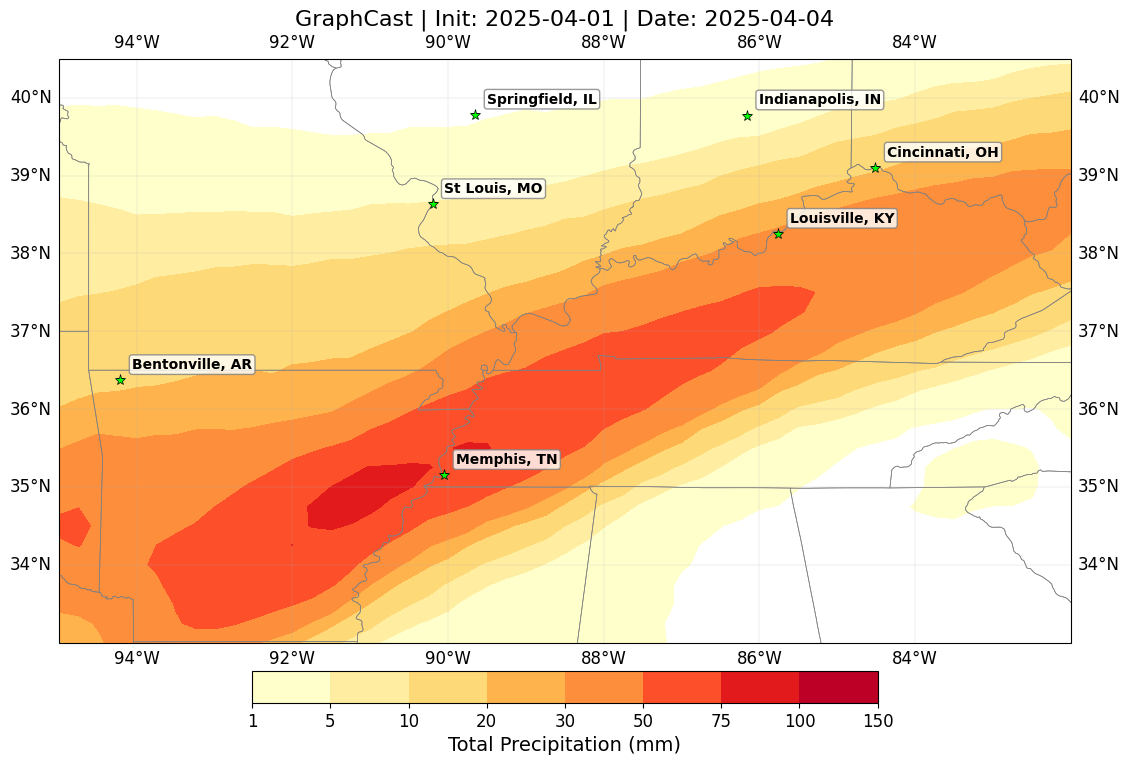

Saved: tn_model_compare_outputs/graphcast_daily_2025-04-05.png


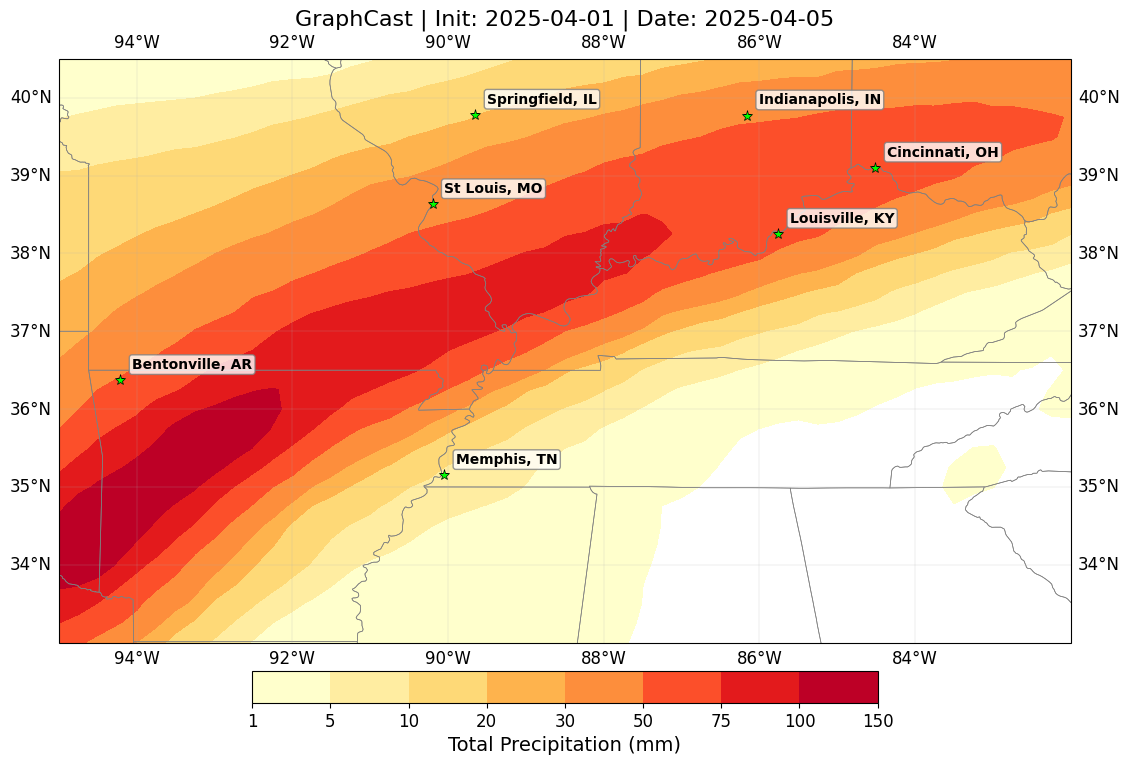

In [9]:
for date in COMPARE_DATES_2M:
    precip = compute_daily_total_precip(gc_io, date, FORECAST_INIT)
    plot_single_panel(
        precip,
        f"GraphCast | Init: {FORECAST_INIT[:10]} | Date: {date}",
        gc_io["lon"][:], gc_io["lat"][:], EXTENT, poi=CITIES,
        save_path=f"{OUTPUT_DIR}/graphcast_daily_{date}.png",
    )

### AIFS daily maps


Saved: tn_model_compare_outputs/aifs_daily_2025-04-04.png


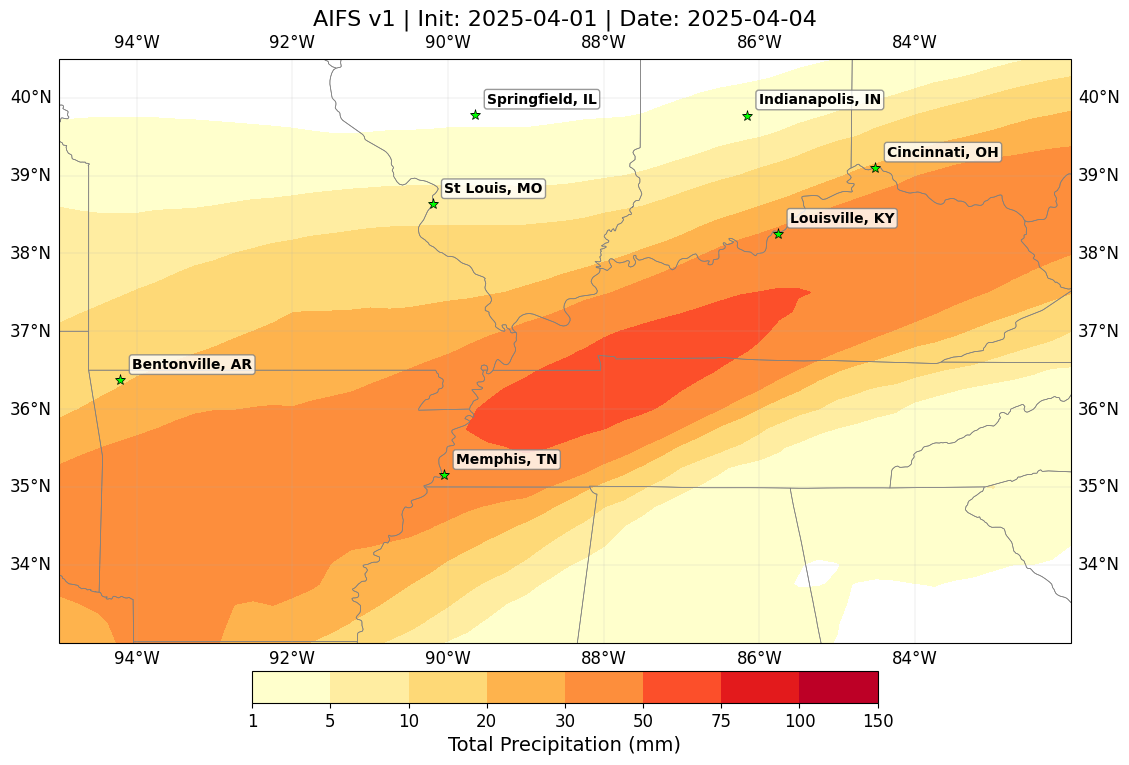

Saved: tn_model_compare_outputs/aifs_daily_2025-04-05.png


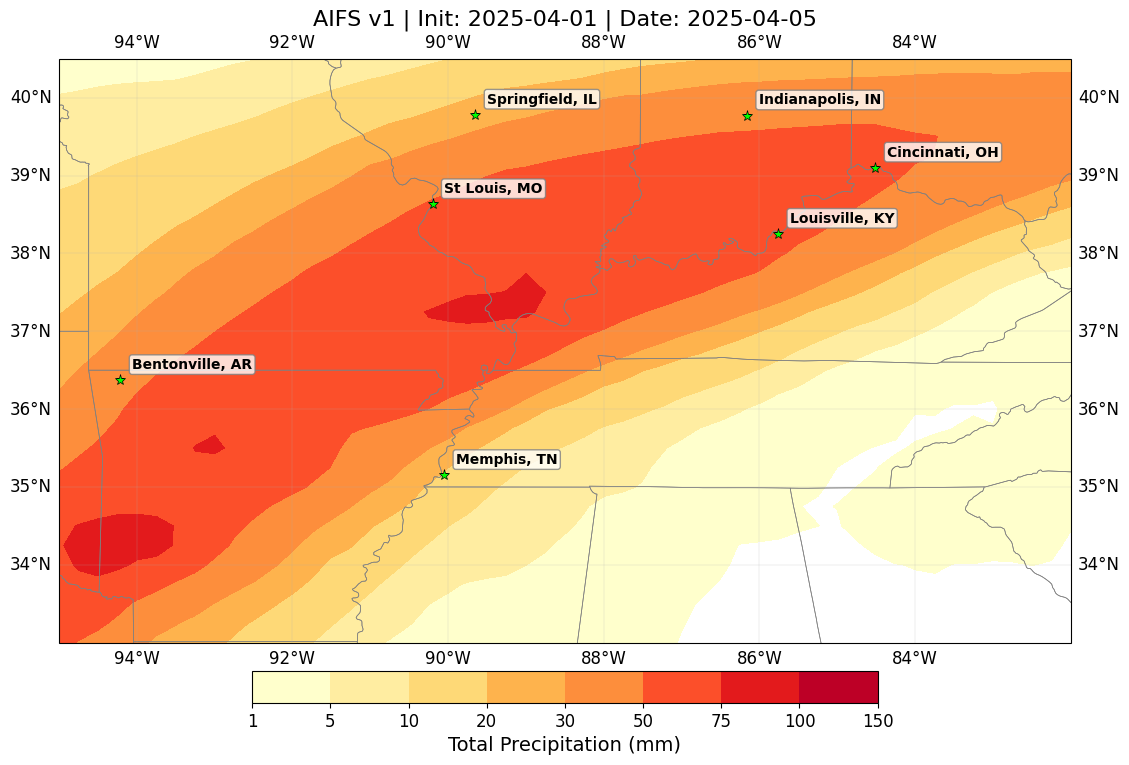

In [10]:
for date in COMPARE_DATES_2M:
    precip = compute_daily_total_precip(aifs_io, date, FORECAST_INIT)
    plot_single_panel(
        precip,
        f"AIFS v1 | Init: {FORECAST_INIT[:10]} | Date: {date}",
        aifs_io["lon"][:], aifs_io["lat"][:], EXTENT, poi=CITIES,
        save_path=f"{OUTPUT_DIR}/aifs_daily_{date}.png",
    )

**How to read this.** Each map is one UTC day (00Z to 00Z) from the 1 April forecasts, so 4 April is a 4-day and 5 April a 5-day forecast. Colours run from red (light, from 1 mm) to blue-purple (heavy, 150 mm and more); white means less than 1 mm. The green stars mark the cities in the table below. Compare the position and size of the heavy band between the GraphCast and AIFS maps for the same day.

## 8 · Side-by-side comparison — maps, city table, domain max

The same day from both models in one figure, the daily totals at each city next to ERA5, and each model's heaviest daily total in the region.

Saved: tn_model_compare_outputs/model_compare_2025-04-04.png


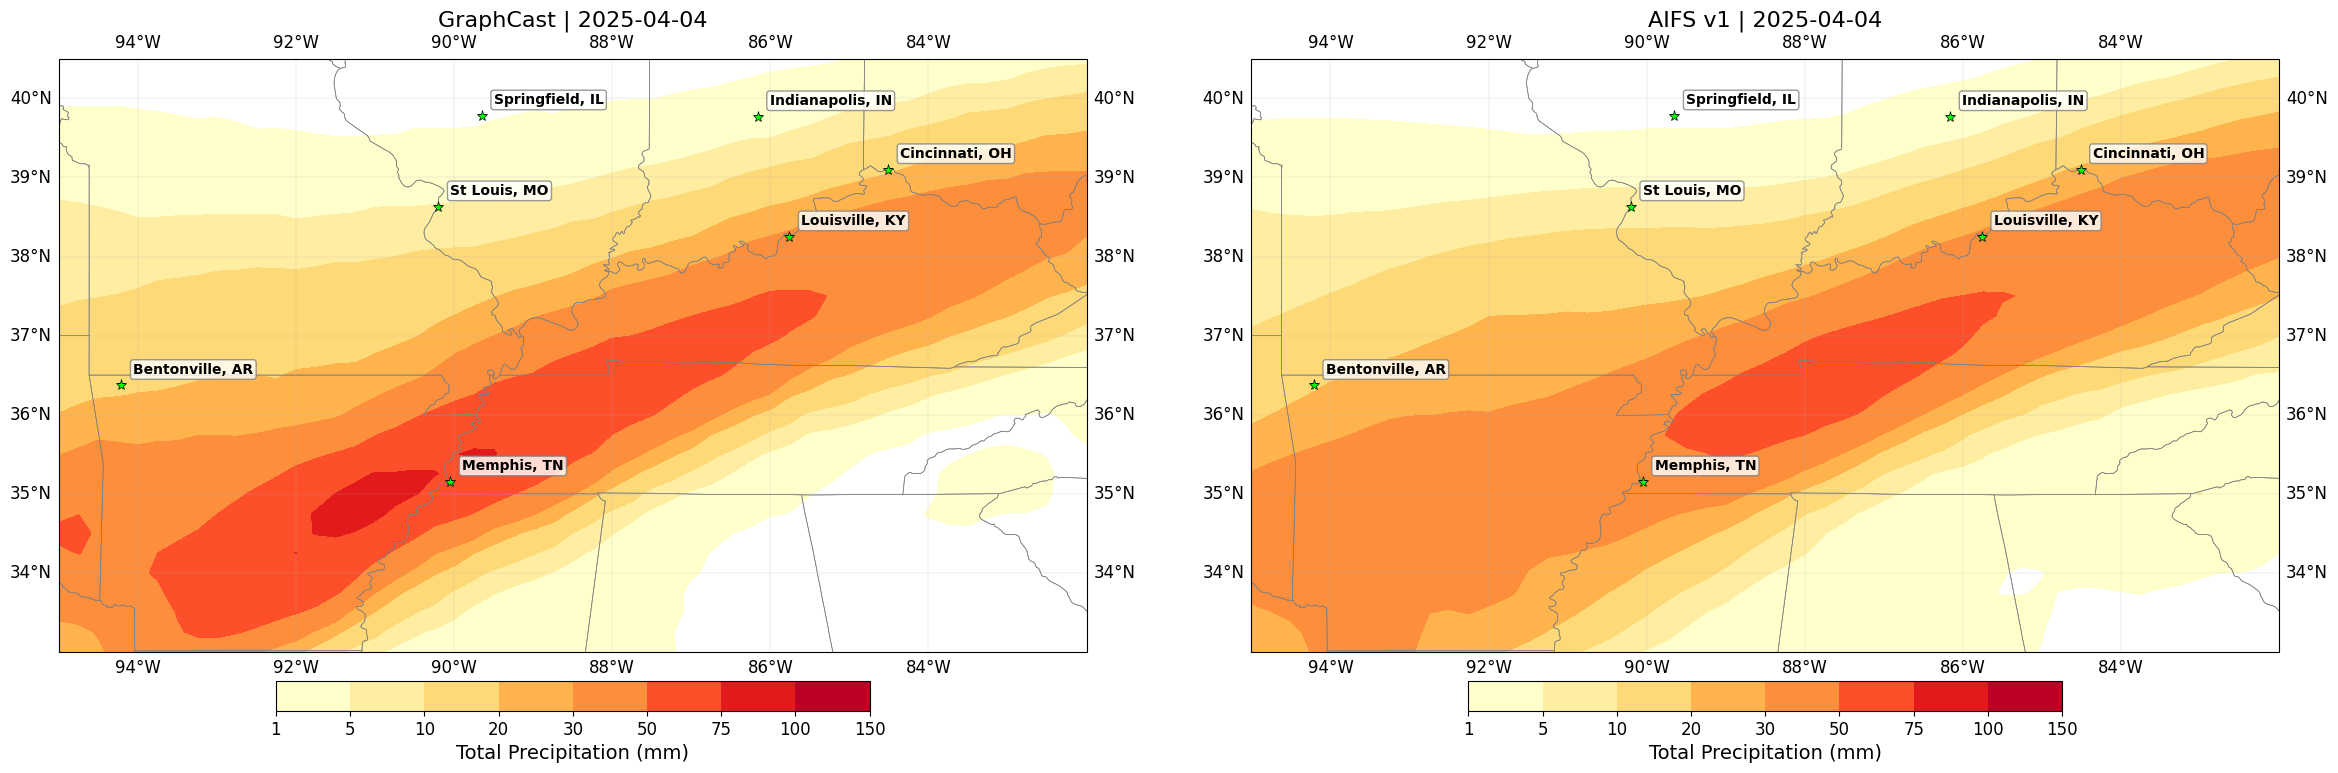


=== 2025-04-04 — daily precipitation (mm) at cities ===
                  GraphCast   AIFS  MRMS  CMORPH  GHCND
City                                                   
Springfield, IL        0.75   0.67   NaN     NaN    NaN
Indianapolis, IN       2.96   2.54   NaN     NaN    NaN
Cincinnati, OH        21.04  24.10   NaN     NaN    NaN
St Louis, MO           4.28   6.06   NaN     NaN    NaN
Louisville, KY        32.56  32.72   NaN     NaN    NaN
Bentonville, AR       19.62  20.19   NaN     NaN    NaN
Memphis, TN           73.17  43.79   NaN     NaN    NaN
Nashville, TN         43.42  45.41   NaN     NaN    NaN
Saved: tn_model_compare_outputs/model_comparison_2025-04-04.csv


Saved: tn_model_compare_outputs/model_compare_2025-04-05.png


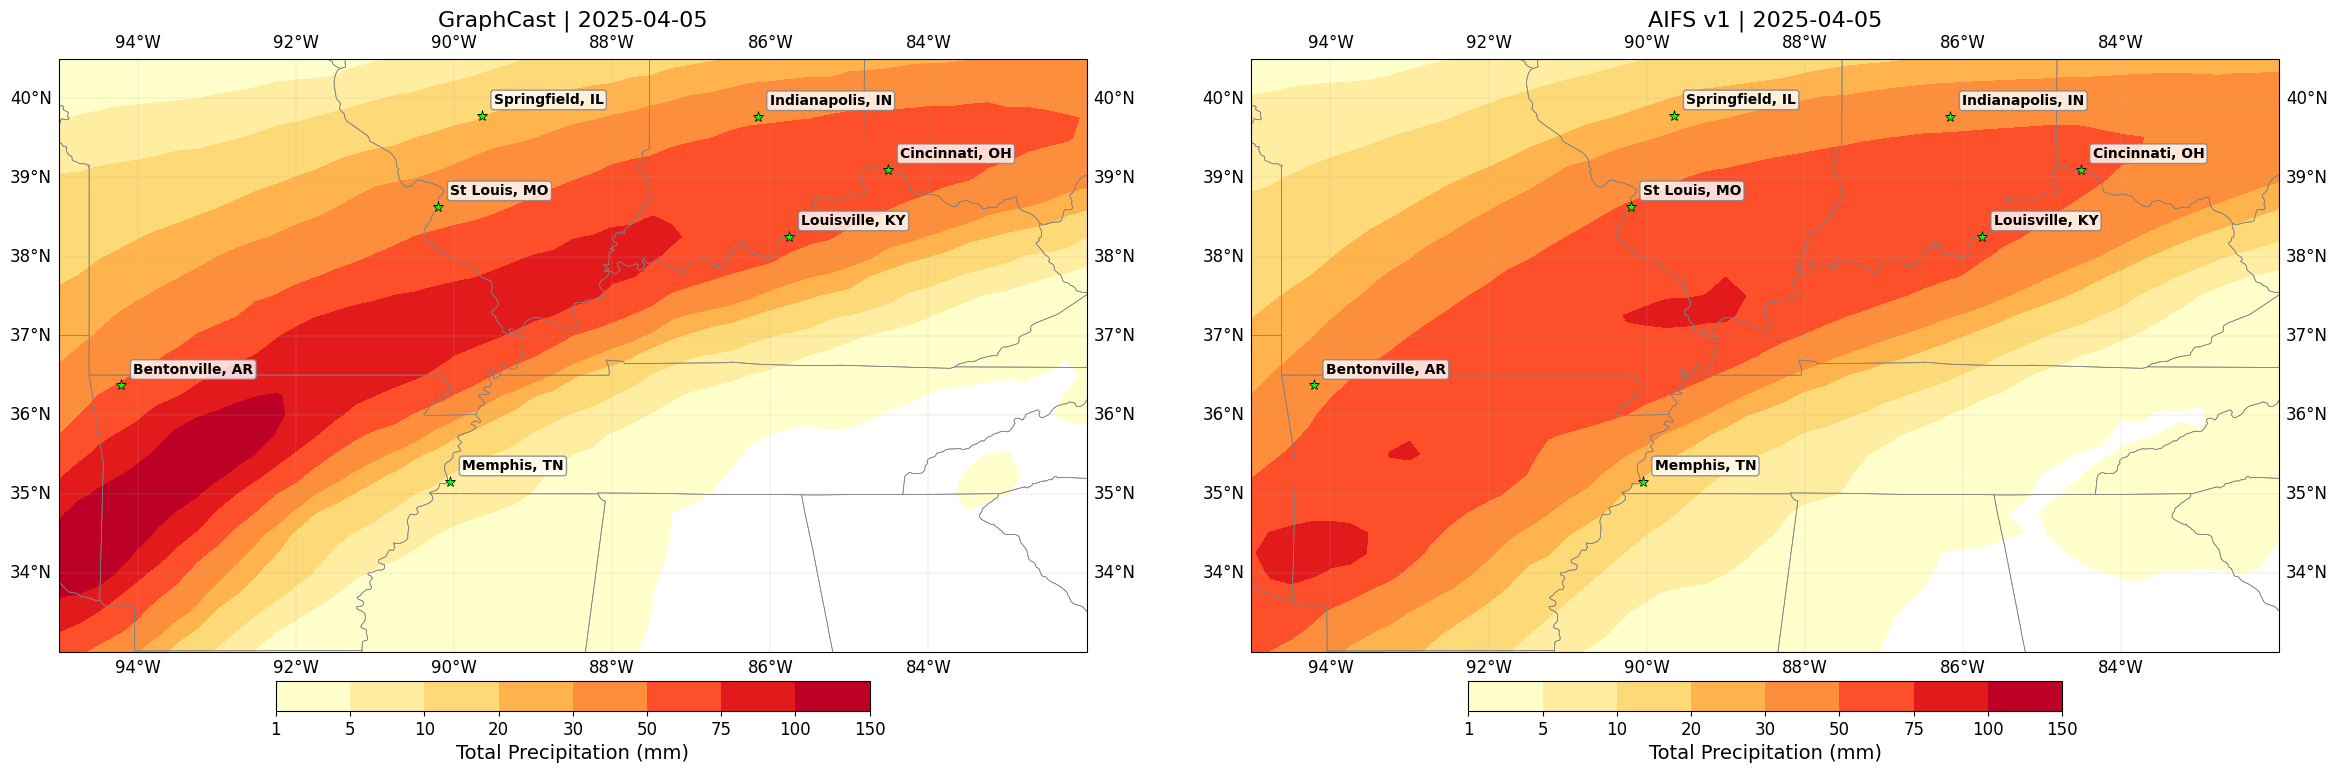


=== 2025-04-05 — daily precipitation (mm) at cities ===
                  GraphCast   AIFS  MRMS  CMORPH  GHCND
City                                                   
Springfield, IL       19.10  24.75   NaN     NaN    NaN
Indianapolis, IN      45.97  45.76   NaN     NaN    NaN
Cincinnati, OH        61.70  52.70   NaN     NaN    NaN
St Louis, MO          37.18  48.09   NaN     NaN    NaN
Louisville, KY        59.88  55.48   NaN     NaN    NaN
Bentonville, AR       54.40  43.09   NaN     NaN    NaN
Memphis, TN            9.31  20.04   NaN     NaN    NaN
Nashville, TN          3.97  10.17   NaN     NaN    NaN
Saved: tn_model_compare_outputs/model_comparison_2025-04-05.csv

=== Domain-max precipitation and location (within TN extent) ===
       model        date  max_mm    lat    lon
0  GraphCast  2025-04-04   82.33  35.00 -91.00
1       AIFS  2025-04-04   62.43  36.25 -88.00
2  GraphCast  2025-04-05  126.01  34.25 -94.75
3       AIFS  2025-04-05   81.09  34.25 -94.00
Saved: tn_model_co

In [11]:
lon = gc_io["lon"][:]
lat = gc_io["lat"][:]

table_cities = CITIES + [{"lat": POI_LAT, "lon": POI_LON, "label": POI_LABEL}]
max_records = []

for date in COMPARE_DATES_2M:
    precip_gc = compute_daily_total_precip(gc_io, date, FORECAST_INIT)
    precip_ai = compute_daily_total_precip(aifs_io, date, FORECAST_INIT)
    era5_day = era5_daily.sel(day=np.datetime64(date))

    plot_model_comparison(
        precip_gc, precip_ai, date, lon, lat, EXTENT, CITIES,
        save_path=f"{OUTPUT_DIR}/model_compare_{date}.png",
    )

    rows = {}
    for city in table_cities:
        la = int(np.argmin(np.abs(lat - city["lat"])))
        lo = int(np.argmin(np.abs(lon - city["lon"])))
        rows[city["label"]] = {
            "GraphCast": round(float(precip_gc[la, lo]), 2),
            "AIFS": round(float(precip_ai[la, lo]), 2),
            "ERA5": round(float(era5_day.sel(lat=city["lat"], lon=city["lon"], method="nearest")), 2),
        }
    df = pd.DataFrame.from_dict(rows, orient="index")[["GraphCast", "AIFS", "ERA5"]]
    df.index.name = "City"
    csv_path = f"{OUTPUT_DIR}/model_comparison_{date}.csv"
    df.to_csv(csv_path)
    print(f"\n=== {date} — daily precipitation (mm) at cities ===")
    print(df)
    print(f"Saved: {csv_path}")

    for name, field in [("GraphCast", precip_gc), ("AIFS", precip_ai)]:
        mx, mlat, mlon = domain_max_location(field, lon, lat, EXTENT)
        max_records.append({
            "model": name, "date": date,
            "max_mm": round(mx, 2), "lat": round(mlat, 3), "lon": round(mlon, 3),
        })

max_df = pd.DataFrame(max_records)
max_csv = f"{OUTPUT_DIR}/max_summary.csv"
max_df.to_csv(max_csv, index=False)
print("\n=== Domain-max precipitation and location (within TN extent) ===")
print(max_df)
print(f"Saved: {max_csv}")

**How to read this.** In each figure GraphCast is on top and AIFS v1 below, on the same colour scale, so differences in colour are differences in forecast rain. The city table gives each model's daily total (mm) at the grid cell nearest each city and the ERA5 daily total at the nearest ERA5 grid cell; ERA5 is itself model-derived and smooths local extremes, so treat it as a reference, not a gauge reading. The last table lists each model's largest daily total inside the map extent and where it fell.

## 9 · Nashville time series

A single flooded city shows how the two models' daily totals differ over the whole comparison window.

Saved: tn_model_compare_outputs/nashville_precip.png


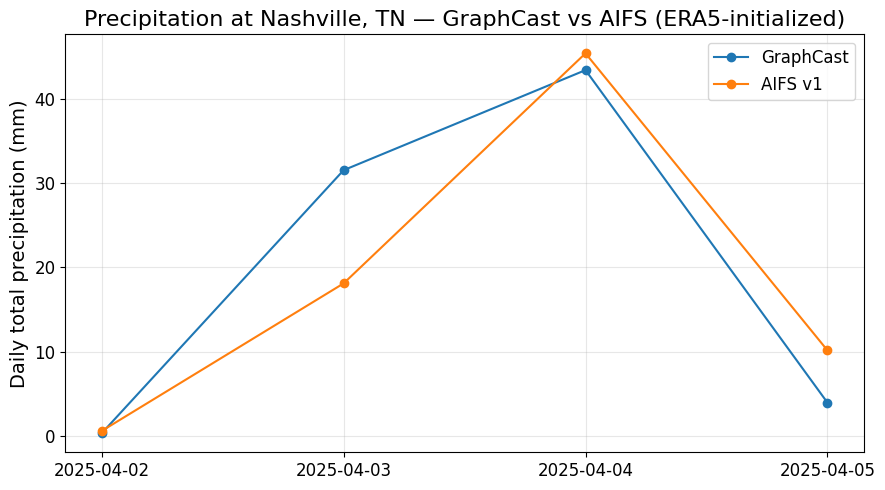

In [12]:
lat_idx = int(np.argmin(np.abs(gc_io["lat"][:] - POI_LAT)))
lon_idx = int(np.argmin(np.abs(gc_io["lon"][:] - POI_LON)))

vals_gc = [compute_daily_total_precip(gc_io, d, FORECAST_INIT)[lat_idx, lon_idx] for d in COMPARE_DATES]
vals_ai = [compute_daily_total_precip(aifs_io, d, FORECAST_INIT)[lat_idx, lon_idx] for d in COMPARE_DATES]

plt.close("all")
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(COMPARE_DATES, vals_gc, marker="o", label="GraphCast")
ax.plot(COMPARE_DATES, vals_ai, marker="o", label="AIFS v1")
ax.set_ylabel("Daily total precipitation (mm)", fontsize=14)
ax.set_title(f"Precipitation at {POI_LABEL} — GraphCast vs AIFS (ERA5-initialized)", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/nashville_precip.png", dpi=150, bbox_inches="tight")
print("Saved:", f"{OUTPUT_DIR}/nashville_precip.png")
plt.show()

**How to read this.** Each line is one model's daily total (mm) at the grid cell nearest Nashville for April 2–5, both from the same 1 April ERA5 start. Where the lines diverge the models disagree on the point forecast; a single grid cell is noisy, so read this together with the maps and the ERA5 scores.

## Summary

- **ERA5 skill tables (section 6):** over the Tennessee Valley box, which model is closer to ERA5 in amount (Bias, RMSE, MAE) and in pattern (Pattern corr), and does the answer change from day to day? ERA5 precipitation is itself model-derived.
- **Daily maps (section 7):** where does each model put the heavy rain on 4 and 5 April?
- **Side-by-side figures, city table and domain maximum (section 8):** how do the two models differ on the same day, how do their city values compare with ERA5, and how intense and where is each model's peak?
- **Nashville time series (section 9):** how do the two models' daily totals at one flooded city compare over April 2–5?

The scores are saved to `docs/results/tennessee_valley_flood_model_comparison_metrics.csv` (mean over April 2–5) and `docs/results/tennessee_valley_flood_model_comparison_daily.csv` (per day); the figures and the per-date city tables are in `tn_model_compare_outputs/`.